In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import yfinance as yf

prices = yf.download(
    ["V", "MA"],
    start="2016-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)["Close"].dropna()

train_prices = prices.loc["2016-01-01":"2021-12-31"]
log_train = np.log(train_prices)

In [4]:
Y = log_train["MA"]
X = log_train["V"]

X_const = sm.add_constant(X)

ols_model = sm.OLS(Y, X_const).fit()

static_alpha = ols_model.params["const"]
static_beta = ols_model.params["V"]

print(f"Static Alpha: {static_alpha:.4f}")
print(f"Static Beta:  {static_beta:.4f}")

Static Alpha: -0.8693
Static Beta:  1.2559


DEFINING Q and R for The Kalman Filter

In [6]:
R = ols_model.mse_resid
q = 1e-5

Q = q * np.eye(2)

In [7]:
theta = np.array([
    static_alpha,
    static_beta
])

P = np.eye(2)

I = np.eye(2)

In [8]:
results = []

for date in log_train.index:

    x_t = log_train.loc[date, "V"]
    y_t = log_train.loc[date, "MA"]

    # Observation matrix
    H = np.array([[1.0, x_t]])

    # -------------------------
    # 1. PREDICT
    # -------------------------

    theta_pred = theta.copy()

    P_pred = P + Q

    y_pred = float((H @ theta_pred)[0])

    # Forecast error
    innovation = y_t - y_pred

    # Forecast error variance
    S = float((H @ P_pred @ H.T)[0, 0] + R)

    # -------------------------
    # 2. KALMAN GAIN
    # -------------------------

    K = (P_pred @ H.T) / S

    # -------------------------
    # 3. UPDATE
    # -------------------------

    theta = theta_pred + K.flatten() * innovation

    A = I - K @ H

    P = (
        A @ P_pred @ A.T
        + (K * R) @ K.T
    )

    # Standardized forecast error
    z = innovation / np.sqrt(S)

    results.append({
        "Date": date,
        "Alpha": theta[0],
        "Beta": theta[1],
        "Forecast Error": innovation,
        "Forecast Variance": S,
        "Z Score": z
    })

In [9]:
kalman = pd.DataFrame(results).set_index("Date")

kalman.head()

,Alpha,Beta,Forecast Error,Forecast Variance,Z Score
Date,,,,,
2016-01-04,-0.868412,1.259851,0.017785,19.069881,0.004073
2016-01-05,-0.863001,1.257615,-0.007553,0.002245,-0.159402
2016-01-06,-0.865823,1.258055,-0.002260,0.001772,-0.053698
2016-01-07,-0.848153,1.254350,0.005190,0.001673,0.126874
2016-01-08,-0.850204,1.254789,-0.000541,0.001635,-0.013371


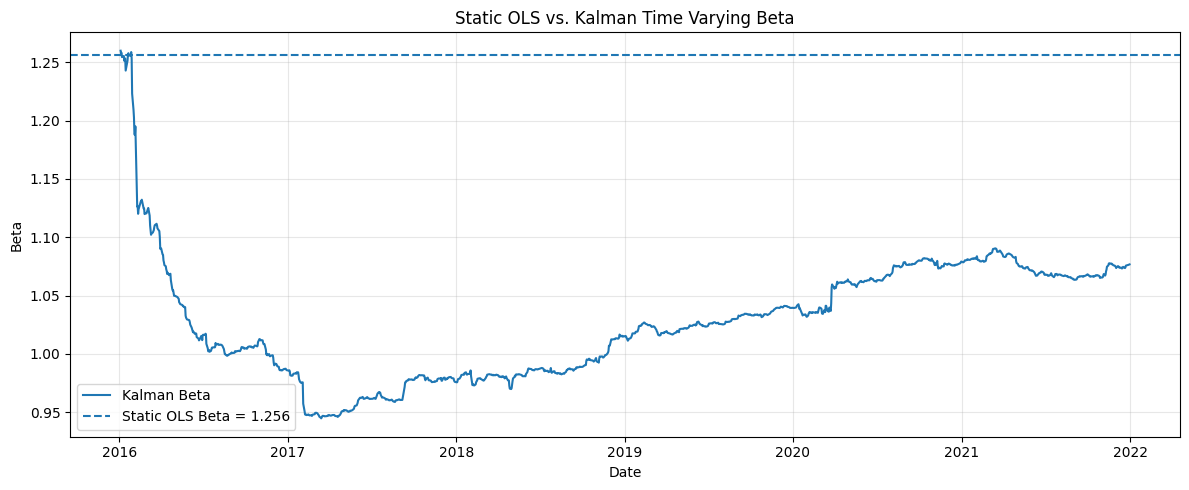

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(
    kalman.index,
    kalman["Beta"],
    label="Kalman Beta"
)

plt.axhline(
    static_beta,
    linestyle="--",
    label=f"Static OLS Beta = {static_beta:.3f}"
)

plt.title("Static OLS vs. Kalman Time Varying Beta")
plt.xlabel("Date")
plt.ylabel("Beta")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

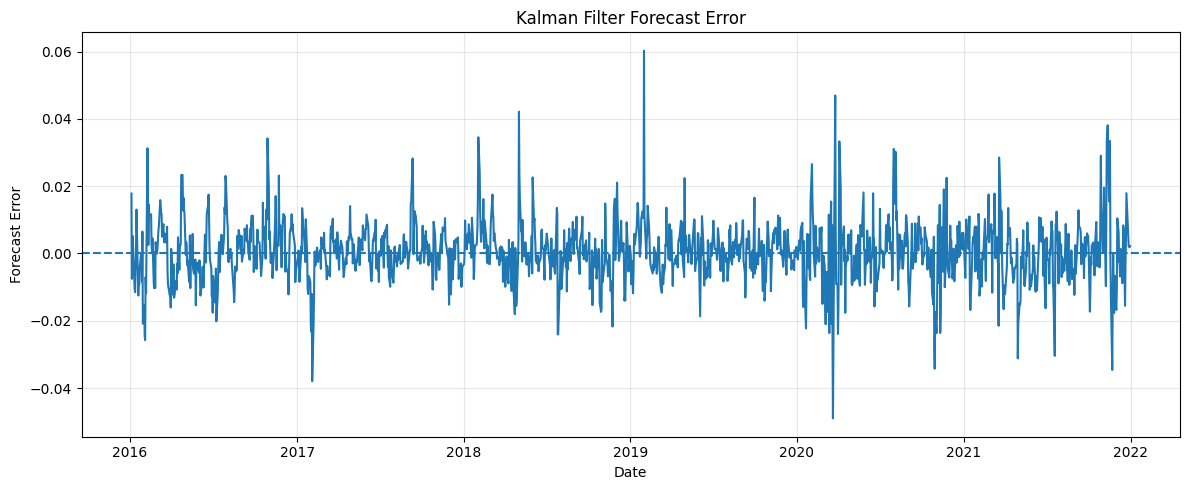

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(
    kalman.index,
    kalman["Forecast Error"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Kalman Filter Forecast Error")
plt.xlabel("Date")
plt.ylabel("Forecast Error")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

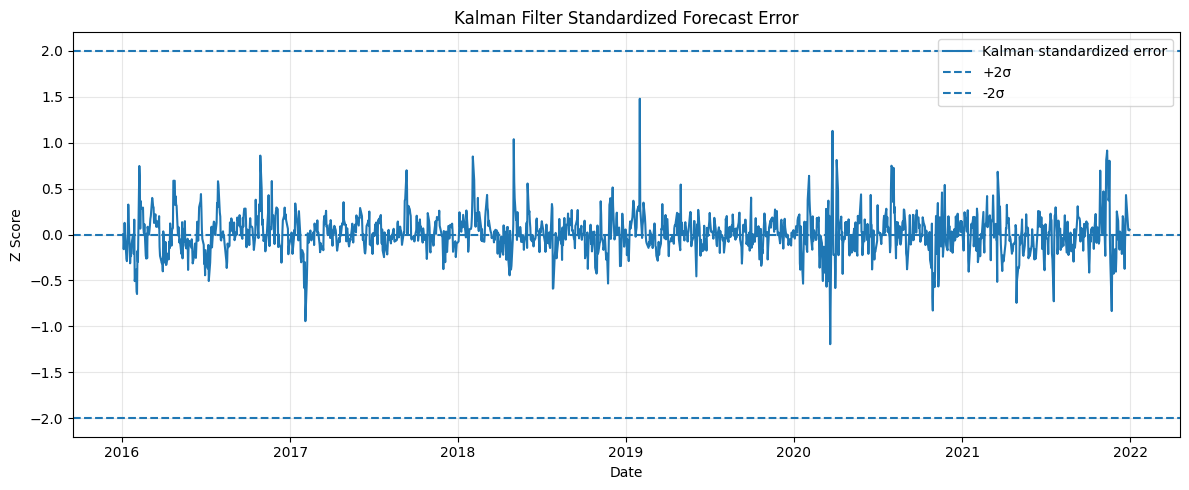

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    kalman.index,
    kalman["Z Score"],
    label="Kalman standardized error"
)

plt.axhline(0, linestyle="--")
plt.axhline(2, linestyle="--", label="+2σ")
plt.axhline(-2, linestyle="--", label="-2σ")

plt.title("Kalman Filter Standardized Forecast Error")
plt.xlabel("Date")
plt.ylabel("Z Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [13]:
print(f"Static OLS Beta: {static_beta:.4f}")

print(
    f"Kalman Beta Minimum: "
    f"{kalman['Beta'].min():.4f}"
)

print(
    f"Kalman Beta Maximum: "
    f"{kalman['Beta'].max():.4f}"
)

print(
    f"Kalman Beta Final: "
    f"{kalman['Beta'].iloc[-1]:.4f}"
)

Static OLS Beta: 1.2559
Kalman Beta Minimum: 0.9448
Kalman Beta Maximum: 1.2599
Kalman Beta Final: 1.0767
